In [3]:
# Setup
include("detector.jl")

fs = 2e6 # Sampling Frequency of 2MHz
T = 1/fs # Sampling Period
n = 40e6
t = (0:n-1)*T
signal_samples = 224 # 112 bits at 1/2 bit per sample (transmission is 1Mb/s)
preamble_samples = 16;

In [4]:
# Read Samples
raw = read("/Users/caio.tavares/dev/personal/sdr/adsb/recordings/adsb-40-2.bin")
iq = to_complex(raw)
m = abs.(iq);

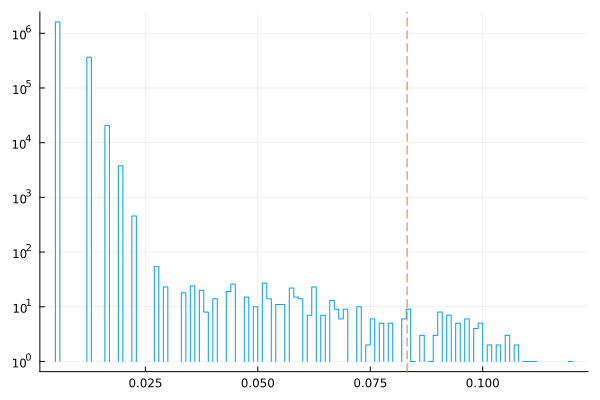

In [5]:
# Define a magnitude threshold
threshold = 15*median(m)
histogram(m[1:2_000_000]; bins = 200, yscale = :log10, legend = false)
vline!([threshold], ls = :dash)

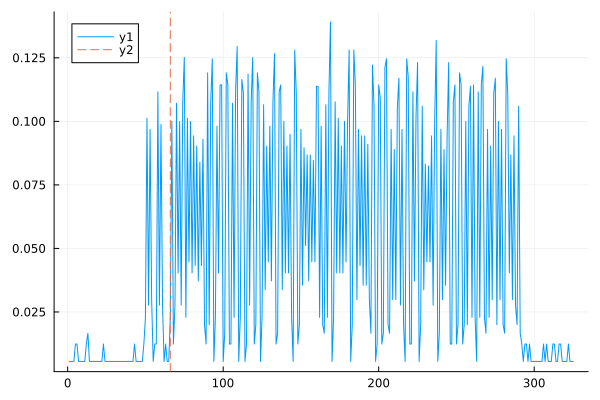

In [6]:
# Signal Sample
top = score(m, threshold)[end][1]
spacing = 50
plot(m[top-spacing:top+signal_samples+spacing])
vline!([spacing+16], ls = :dash)

In [7]:
signal = bytes2hex.(detect(iq, threshold)[end-19:end])

20-element Vector{String}:
 "0080084001024004000908085084"
 "1302000405008800800100488000"
 "0020000120010800c00000100460"
 "010904508486008101000c000041"
 "8fe4a5285e81b05f5a69438b99e4"
 "5fe4a528d11217d0404100000210"
 "8fe4a52899154c8238643ca10547"
 "8fe4a528ea159858013c08b65b1f"
 "8fe4a5285881e4a212b24e457700"
 "8fe4a5285881c05f5e697e181152"
 "8fe4a52899154b8218643d12b90d"
 "8fe4a528ea159858013c08b65b1f"
 "8fe4a52899154b8218643d12b90d"
 "8fe4a5285e81805f5068e25858b7"
 "8fe4a5285e81b05f5c695da7d4fb"
 "5fe4a528d112179000a0021a2000"
 "5fe4a528d11217c0008000048004"
 "8fe4a528f82300020049788013fd"
 "8fe4a528e11e3e0000000012d455"
 "8fe4a5285e81905f54690454c8ee"